# Time series of the yearly responses, 2001–2014

Yearly mean differences of the variables of the BVOC/SOA/cloud context maps (`forcing_maps.CONTEXT_PANELS`, e.g. `FUT_fBVOCctrlFUT_bvoc_context_maps_2001_2014.png`) and of the NET Ghan (2013) terms, one figure per contrast (§1–2); absolute values of every nudged run in §3.

**Two lines per panel**
- **global**: area-weighted global mean (land-only fields such as ET: global land mean, weights = cell area × land fraction);
- **regional**: **modified cells** for the BVOC emissions (ISOP, MTERP), **≥45°N** for all other variables.

Dashed horizontal line = mean over the years of that line; legend = mean ± 95 % CI (t-interval over years).

**Data and caveats**
- Input: `data/processed-data/postprocessing/<alias>_<atm|lnd>_<CAT>_2001-2014.nc`, CO₂-fix (new) chain, all runs archived and postprocessed by 2026-11-02.
- **Year 2000 is not shown:** it is the first 12 months of every nudged run, dropped as spin-up in postprocessing (`--spinup-months 12`).
- **BVOC contrasts are artefact-corrected** (design B, `analysis/FBVOC_ARTEFACT.md`): LCC_P − (LCC_P_fBVOC<E> − CTRL_P_fBVOCctrlP + CTRL_P) = (LCC_P − LCC_P_fBVOC<E>) + art_P (`forcing_maps.corrected_fbvoc`). The uncorrected versions are in `results/figures/pre-artefact-correction/`.
- `BVOC_FUT` (emissions from CTRL_PD) mixes the 2100 background with the land-cover change; it is **not** the forest-expansion-only BVOC effect. The `fBVOCctrlFUT` row uses CTRL_FUT emissions.
- Means are over yearly area-weighted means of month-length-weighted annual means; in-cloud values (droplet radius and number) are yearly ratios of means with FCTL ≥ 0.01, as in the maps.
- Ghan: positive = downward = warming; total = ARI + cloud + rest, closure checked below.


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # repo src/, no pip install needed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm
from boreal_forest_expansion.plotting import palette as pal

set_default_style()
START_YEAR, END_YEAR = 2001, 2014
FIGDIR = fm.FIGURE_DIR / "timeseries"
TABLE = fm.REPO_DIR / "results" / "tables" / f"timeseries_regional_means_{START_YEAR}_{END_YEAR}.csv"
FIGDIR.mkdir(parents=True, exist_ok=True)

# label -> (case1, case2); case2 may be a VirtualRun (artefact-corrected fBVOC reference)
CONTRASTS = {
    "Total_PD":  ("LCC_PD", "CTRL_PD"),
    "Total_FUT": ("LCC_FUT", "CTRL_FUT"),
    "Background_FUT": ("CTRL_FUT", "CTRL_PD"),
    "BVOC_PD_fBVOCctrlPD_corr": ("LCC_PD", fm.corrected_fbvoc("PD")),
    "BVOC_FUT_fBVOCctrlPD_corr": ("LCC_FUT", fm.corrected_fbvoc("FUT", "ctrlPD")),
    "BVOC_FUT_fBVOCctrlFUT_corr": ("LCC_FUT", fm.corrected_fbvoc("FUT", "ctrlFUT")),
}
REGIONAL = {"sfisop": "modified cells", "sfmterp": "modified cells"}   # all other panels: ≥45°N
COLORS = {"global": pal.NAVY, "regional": pal.RED}

# panels: the 9 context maps + the 4 NET Ghan terms
PANELS = [(p.key, p.title, p.variable_class, p.variable, p.units, p.component) for p in fm.CONTEXT_PANELS]
PANELS += [(f"NET_{t}", fm.GHAN_TITLES[t], "RADIATIVE", f"NET_{t}", "W m$^{-2}$", "atm") for t in fm.GHAN_TERMS]

# every run used must exist for 2001-2014
for c1, c2 in CONTRASTS.values():
    for alias in {**fm.run_weights(c1), **fm.run_weights(c2)}:
        for cls, comp in {(p[2], p[5]) for p in PANELS}:
            path = fm.filename(alias, cls, START_YEAR, END_YEAR, comp)
            if not path.exists():
                print("MISSING", path.name)
print("runs checked;", len(CONTRASTS), "contrasts,", len(PANELS), "panels")


runs checked; 6 contrasts, 13 panels


## 1. Yearly global and regional means

Region weights come from a reference file of the same component (CAM and CLM grids differ by ~1e-13 in the coordinates): `fm.region_masks`, `fm.regional`.

In [2]:
refs = {comp: fm.open_class("CTRL_PD", cls, START_YEAR, END_YEAR, comp)
        for comp, cls in (("atm", "RADIATIVE"), ("lnd", "ET"))}
masks = {comp: fm.region_masks(ds) for comp, ds in refs.items()}
for comp, m in masks.items():
    m["global"] = m["≥45°N"] | ~m["≥45°N"]   # all cells

rows = []
for label, (c1, c2) in CONTRASTS.items():
    for key, title, cls, var, units, comp in PANELS:
        d = fm.yearly_difference(c1, c2, cls, var, START_YEAR, END_YEAR, comp)
        for line, region in (("global", "global"), ("regional", REGIONAL.get(key, "≥45°N"))):
            r = fm.regional(d, refs[comp], masks[comp][region])
            rows += [dict(contrast=label, case1=str(c1), case2=str(c2), panel=key, variable=var, line=line,
                          region=region, units=units, year=int(y), value=float(v))
                     for y, v in zip(r["year"].values, r.values)]
t = pd.DataFrame(rows)

# Ghan closure on the regional means: ARI + cloud + rest = total
g = t[t.panel.str.startswith("NET_")].pivot_table(index=["contrast", "line", "year"], columns="variable", values="value")
err = (g["NET_dir"] + g["NET_cloud"] + g["NET_rest"] - g["NET_toa"]).abs().max()
print(f"Ghan closure (regional means): max |ARI + cloud + rest - total| = {err:.1e} W m-2")
assert err < 1e-3
assert t.groupby(["contrast", "panel", "line"]).year.count().eq(END_YEAR - START_YEAR + 1).all()

t.to_csv(TABLE, index=False)
print("Saved", TABLE)


Ghan closure (regional means): max |ARI + cloud + rest - total| = 8.3e-08 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/tables/timeseries_regional_means_2001_2014.csv


In [3]:
def mean_ci(v, conf=0.95):
    v = np.asarray(v)
    return v.mean(), stats.t.ppf(0.5 + conf / 2, v.size - 1) * v.std(ddof=1) / np.sqrt(v.size)

# mean ± 95 % CI over years; `region` = region of the regional line
s = (t.groupby(["contrast", "panel", "units", "line"], sort=False)["value"]
       .apply(lambda v: "{:+.3g} ± {:.2g}".format(*mean_ci(v))).unstack("line"))
s["region"] = t[t.line == "regional"].groupby(["contrast", "panel", "units"], sort=False).region.first()
with pd.option_context("display.max_rows", 200):
    display(s)


line                                                                    global  \
contrast                   panel     units                                       
Total_PD                   sfisop    mg m$^{-2}$ d$^{-1}$    -0.00246 ± 0.0078   
                           sfmterp   mg m$^{-2}$ d$^{-1}$    -0.00085 ± 0.0017   
                           soa_tot   mg m$^{-2}$             -0.00455 ± 0.0093   
                           n_aer     cm$^{-3}$                   +0.997 ± 0.66   
                           fctl      fraction              -1.25e-05 ± 0.00023   
                           actrel    µm                     -0.000266 ± 0.0025   
                           actnl     cm$^{-3}$                -0.00518 ± 0.071   
                           lwp       g m$^{-2}$                -0.0556 ± 0.033   
                           et        mm day$^{-1}$         +0.000762 ± 0.00089   
                           NET_toa   W m$^{-2}$                +0.0307 ± 0.024   
                           NET_dir   W m$^{-2}$              -0.00103 ± 0.0061   
                           NET_cloud W m$^{-2}$               -0.00728 ± 0.021   
                           NET_rest  W m$^{-2}$                +0.039 ± 0.0066   
Total_FUT                  sfisop    mg m$^{-2}$ d$^{-1}$     +0.0115 ± 0.0086   
                           sfmterp   mg m$^{-2}$ d$^{-1}$    +0.00401 ± 0.0041   
                           soa_tot   mg m$^{-2}$               +0.0125 ± 0.014   
                           n_aer     cm$^{-3}$                   +0.569 ± 0.66   
                           fctl      fraction              -3.42e-05 ± 0.00019   
                           actrel    µm                       -0.00634 ± 0.004   
                           actnl     cm$^{-3}$                 +0.0219 ± 0.064   
                           lwp       g m$^{-2}$                -0.0431 ± 0.018   
                           et        mm day$^{-1}$         +0.000224 ± 0.00095   
                           NET_toa   W m$^{-2}$                +0.0141 ± 0.018   
                           NET_dir   W m$^{-2}$                -0.0105 ± 0.012   
                           NET_cloud W m$^{-2}$               -0.00595 ± 0.015   
                           NET_rest  W m$^{-2}$                 +0.0306 ± 0.01   
Background_FUT             sfisop    mg m$^{-2}$ d$^{-1}$        +2.02 ± 0.031   
                           sfmterp   mg m$^{-2}$ d$^{-1}$        +1.97 ± 0.015   
                           soa_tot   mg m$^{-2}$                 +4.22 ± 0.066   
                           n_aer     cm$^{-3}$                      -256 ± 2.7   
                           fctl      fraction               +0.00614 ± 0.00049   
                           actrel    µm                        +0.467 ± 0.0092   
                           actnl     cm$^{-3}$                     -7.37 ± 0.2   
                           lwp       g m$^{-2}$                  +2.38 ± 0.095   
                           et        mm day$^{-1}$           +0.00276 ± 0.0041   
                           NET_toa   W m$^{-2}$                   +2.5 ± 0.072   
                           NET_dir   W m$^{-2}$                 -0.436 ± 0.039   
                           NET_cloud W m$^{-2}$                  +0.36 ± 0.055   
                           NET_rest  W m$^{-2}$                  +2.58 ± 0.038   
BVOC_PD_fBVOCctrlPD_corr   sfisop    mg m$^{-2}$ d$^{-1}$    -0.00246 ± 0.0078   
                           sfmterp   mg m$^{-2}$ d$^{-1}$    -0.00085 ± 0.0017   
                           soa_tot   mg m$^{-2}$              -0.00796 ± 0.012   
                           n_aer     cm$^{-3}$                   +0.425 ± 0.66   
                           fctl      fraction              +8.35e-05 ± 0.00029   
                           actrel    µm                     -6.39e-05 ± 0.0043   
                           actnl     cm$^{-3}$                 +0.0168 ± 0.066   
                           lwp       g m$^{-2}$                -

## 2. Figures: one per contrast

Rows 1–3: context variables (same order as the context maps); row 4: NET Ghan terms (W m⁻²).

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/timeseries/timeseries_Total_PD_2001_2014.png


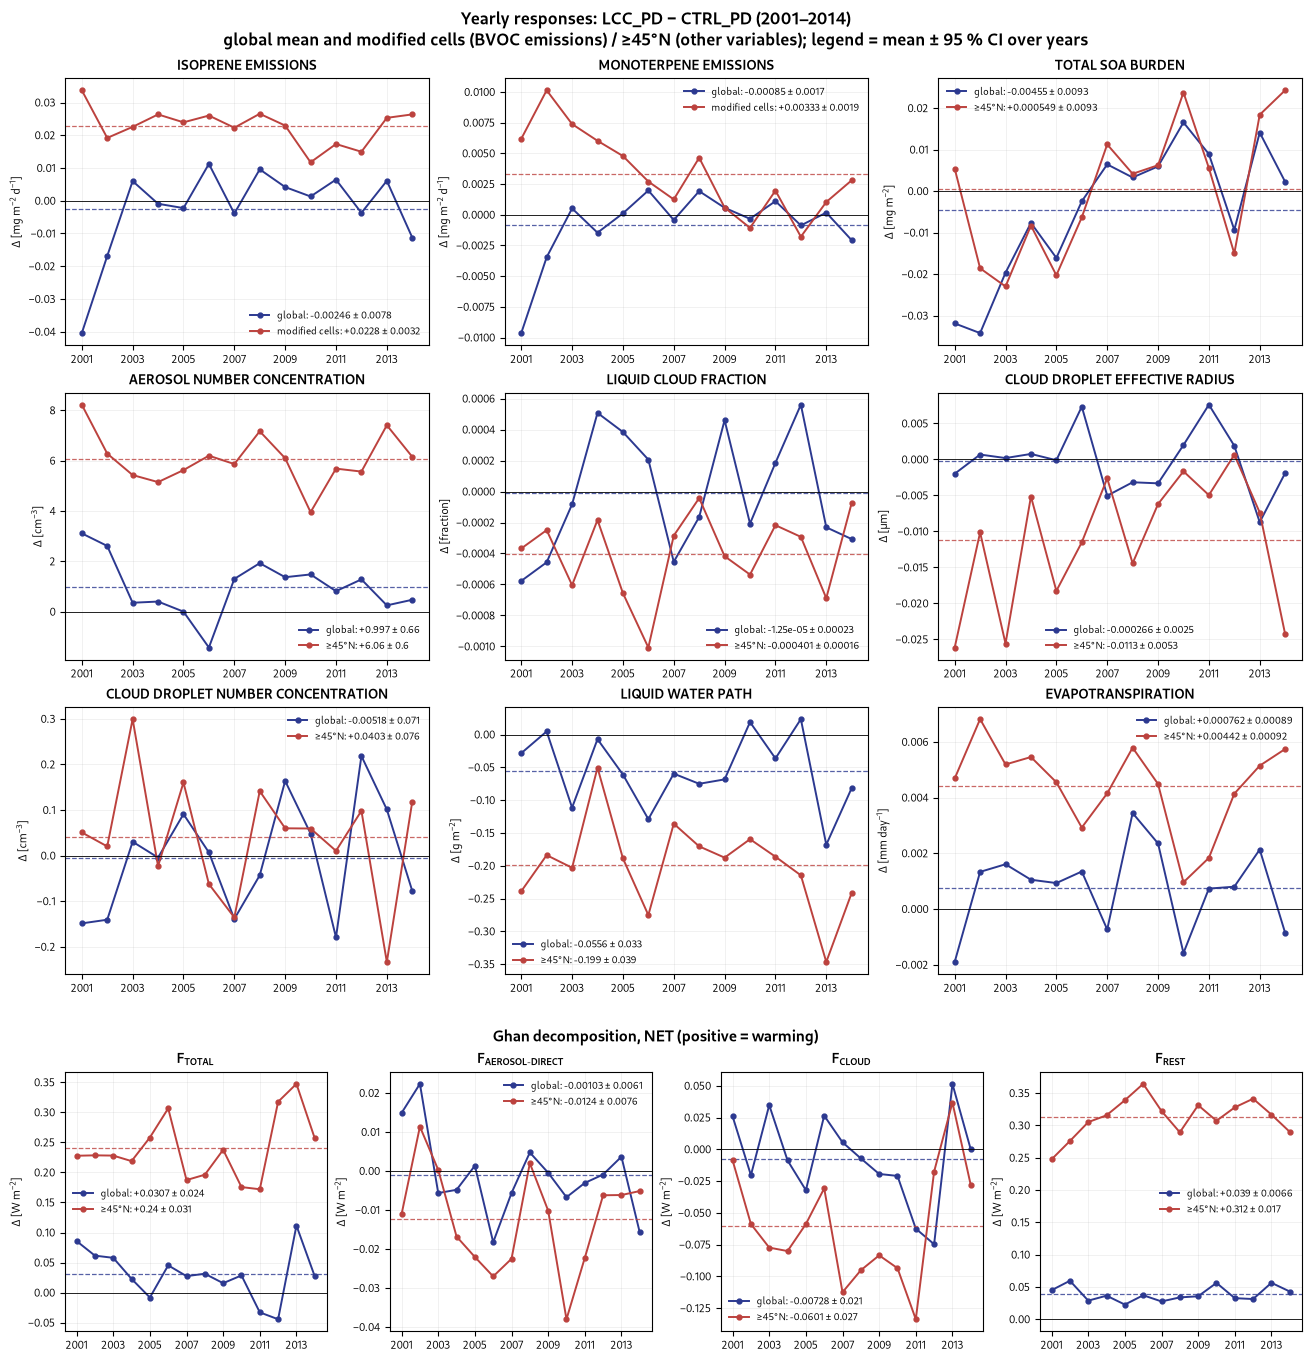

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/timeseries/timeseries_Total_FUT_2001_2014.png


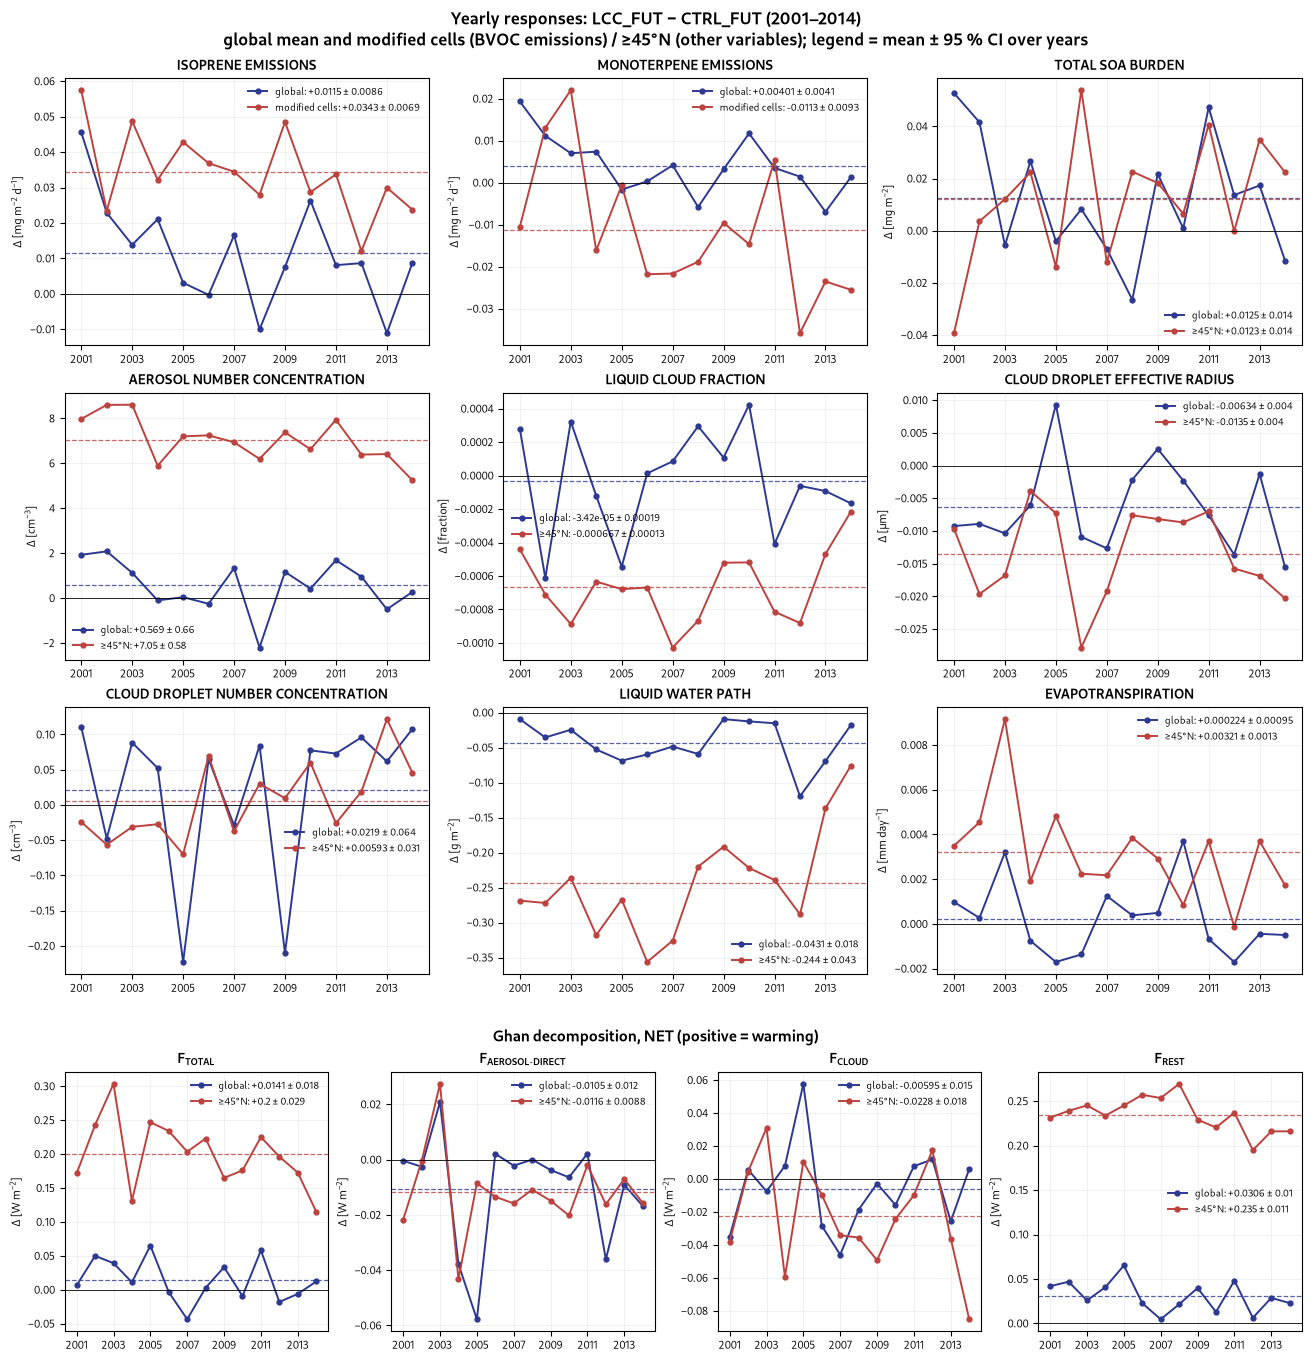

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/timeseries/timeseries_Background_FUT_2001_2014.png


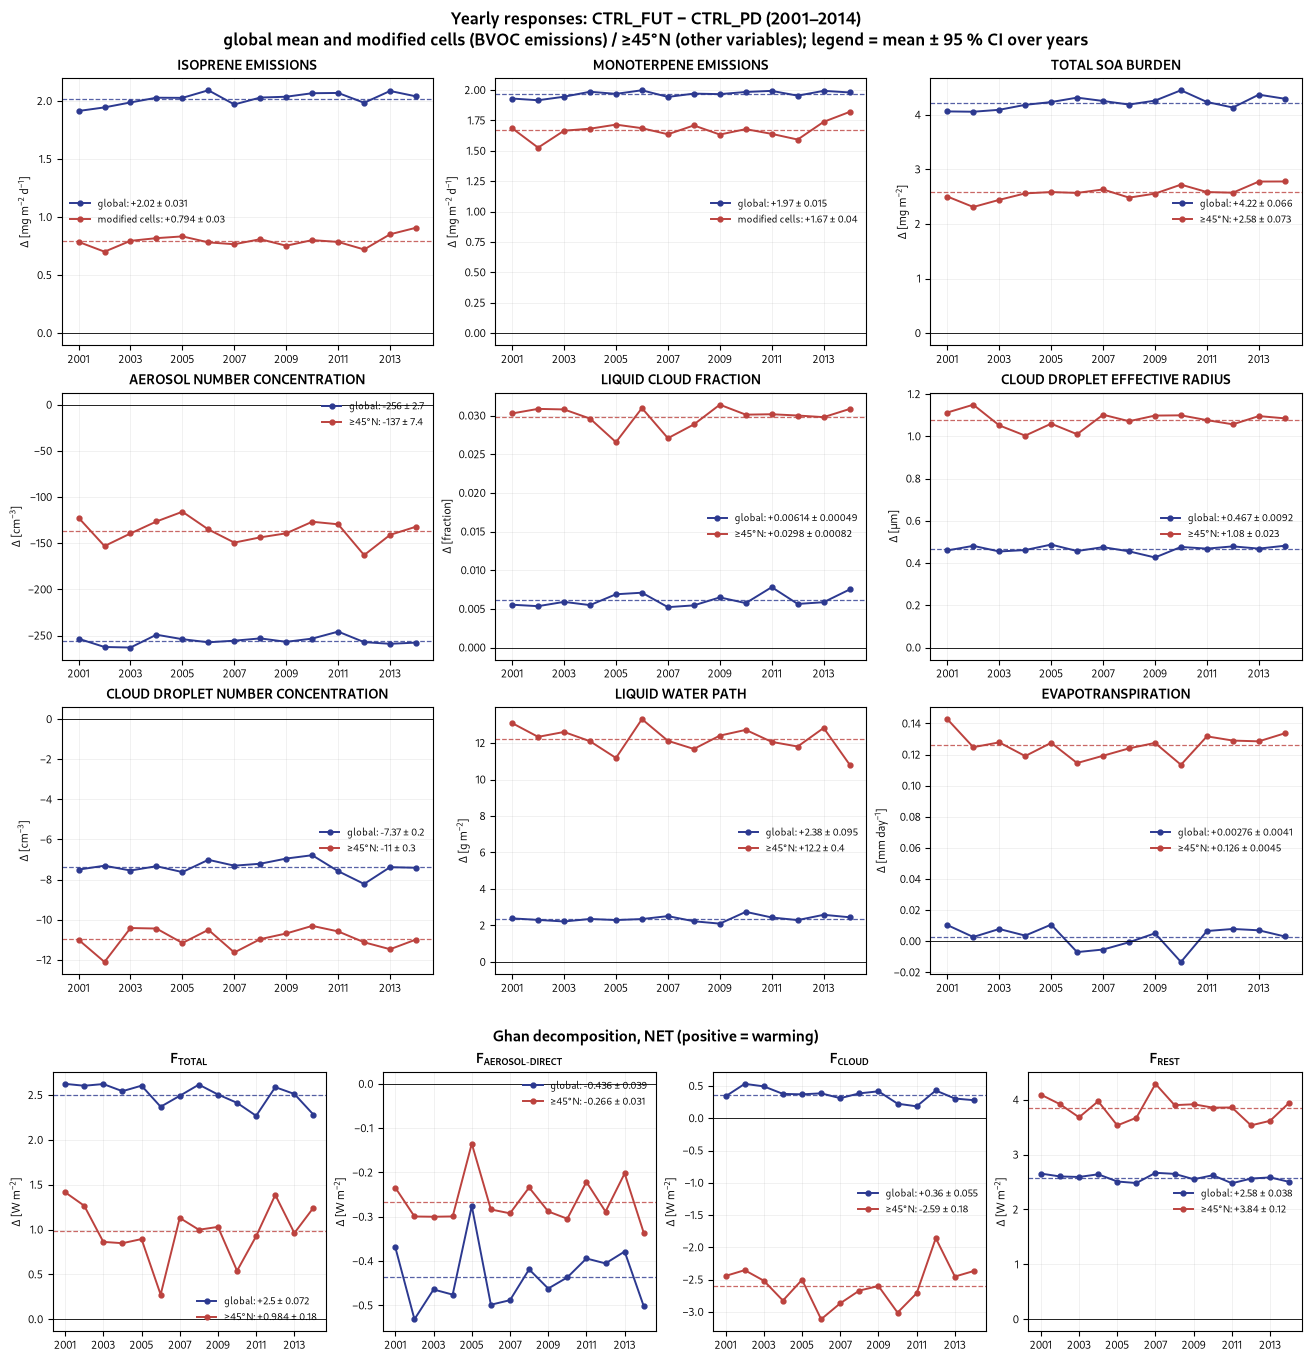

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/timeseries/timeseries_BVOC_PD_fBVOCctrlPD_corr_2001_2014.png


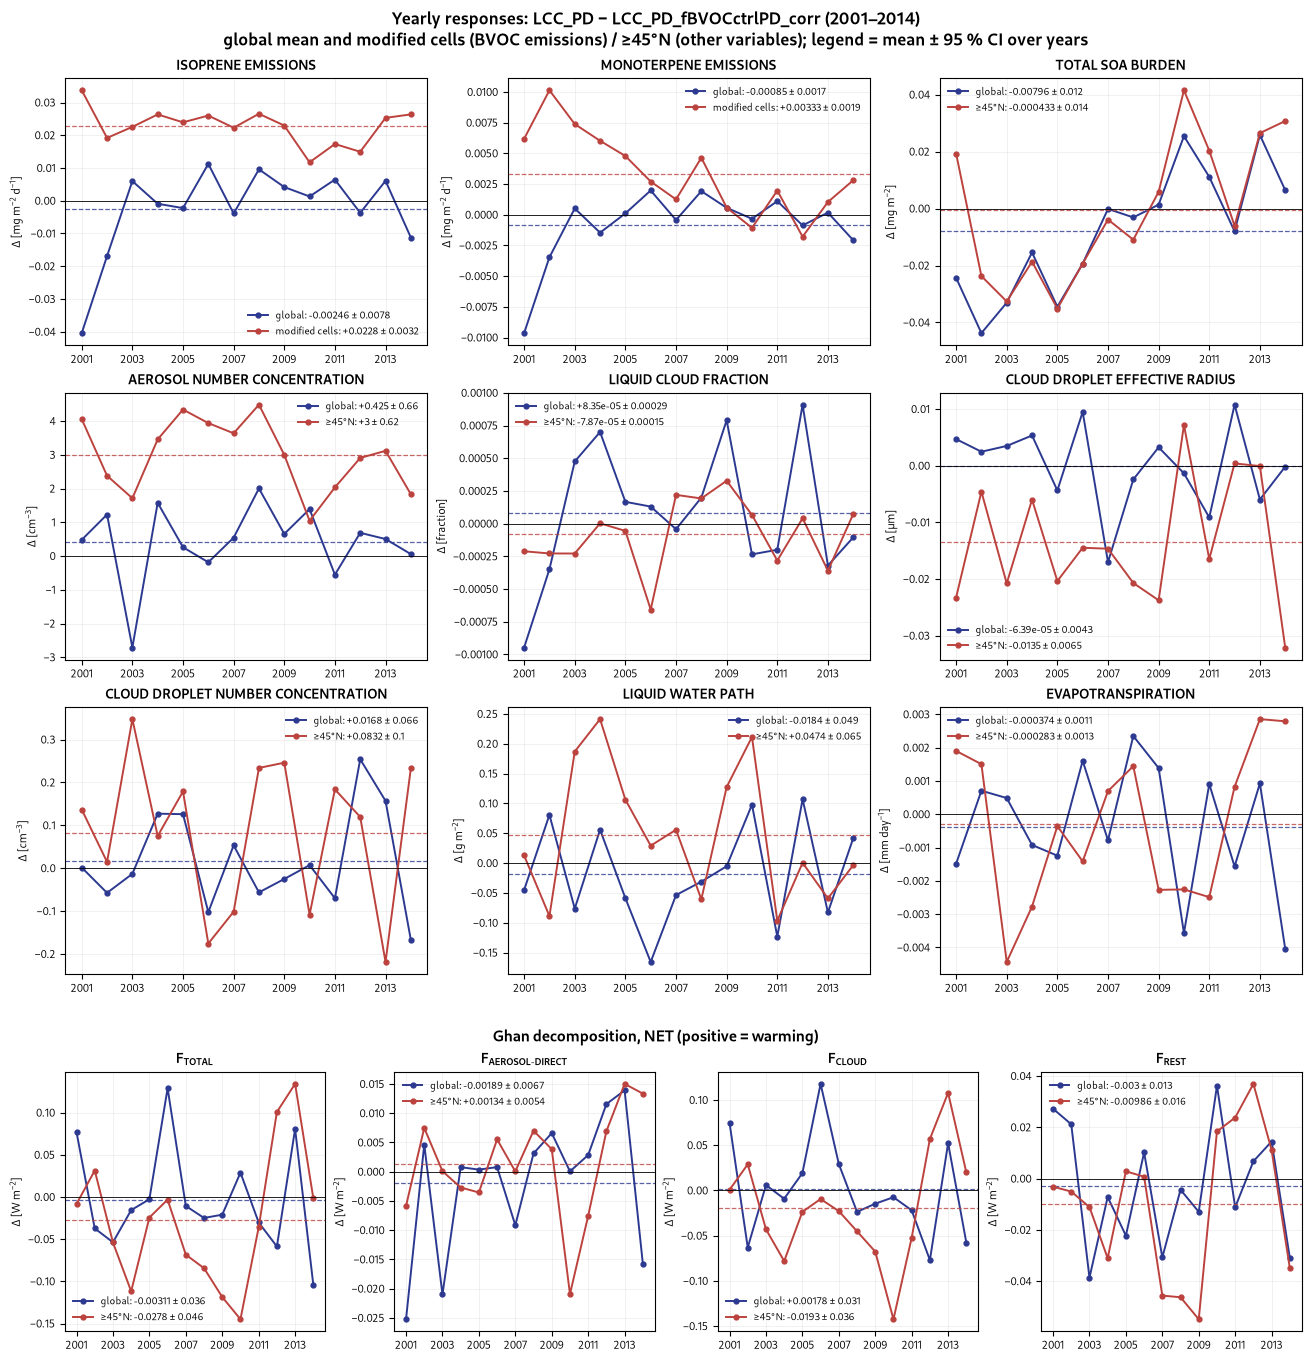

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/timeseries/timeseries_BVOC_FUT_fBVOCctrlPD_corr_2001_2014.png


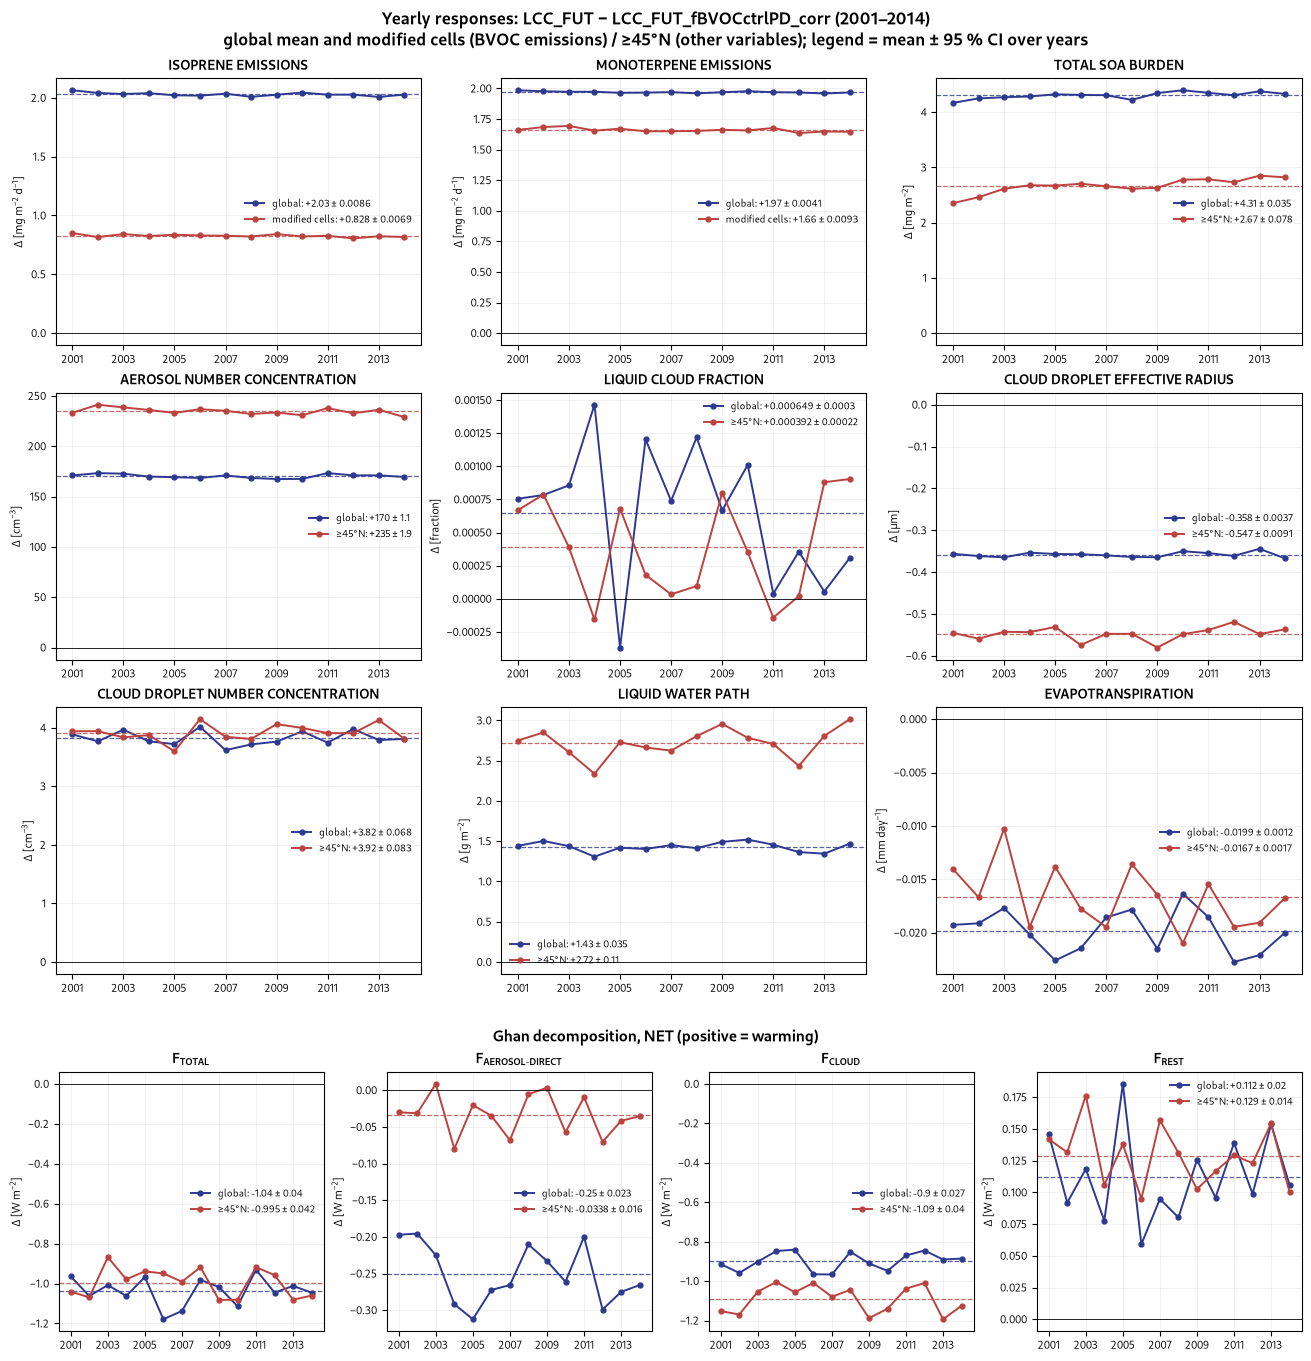

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/timeseries/timeseries_BVOC_FUT_fBVOCctrlFUT_corr_2001_2014.png


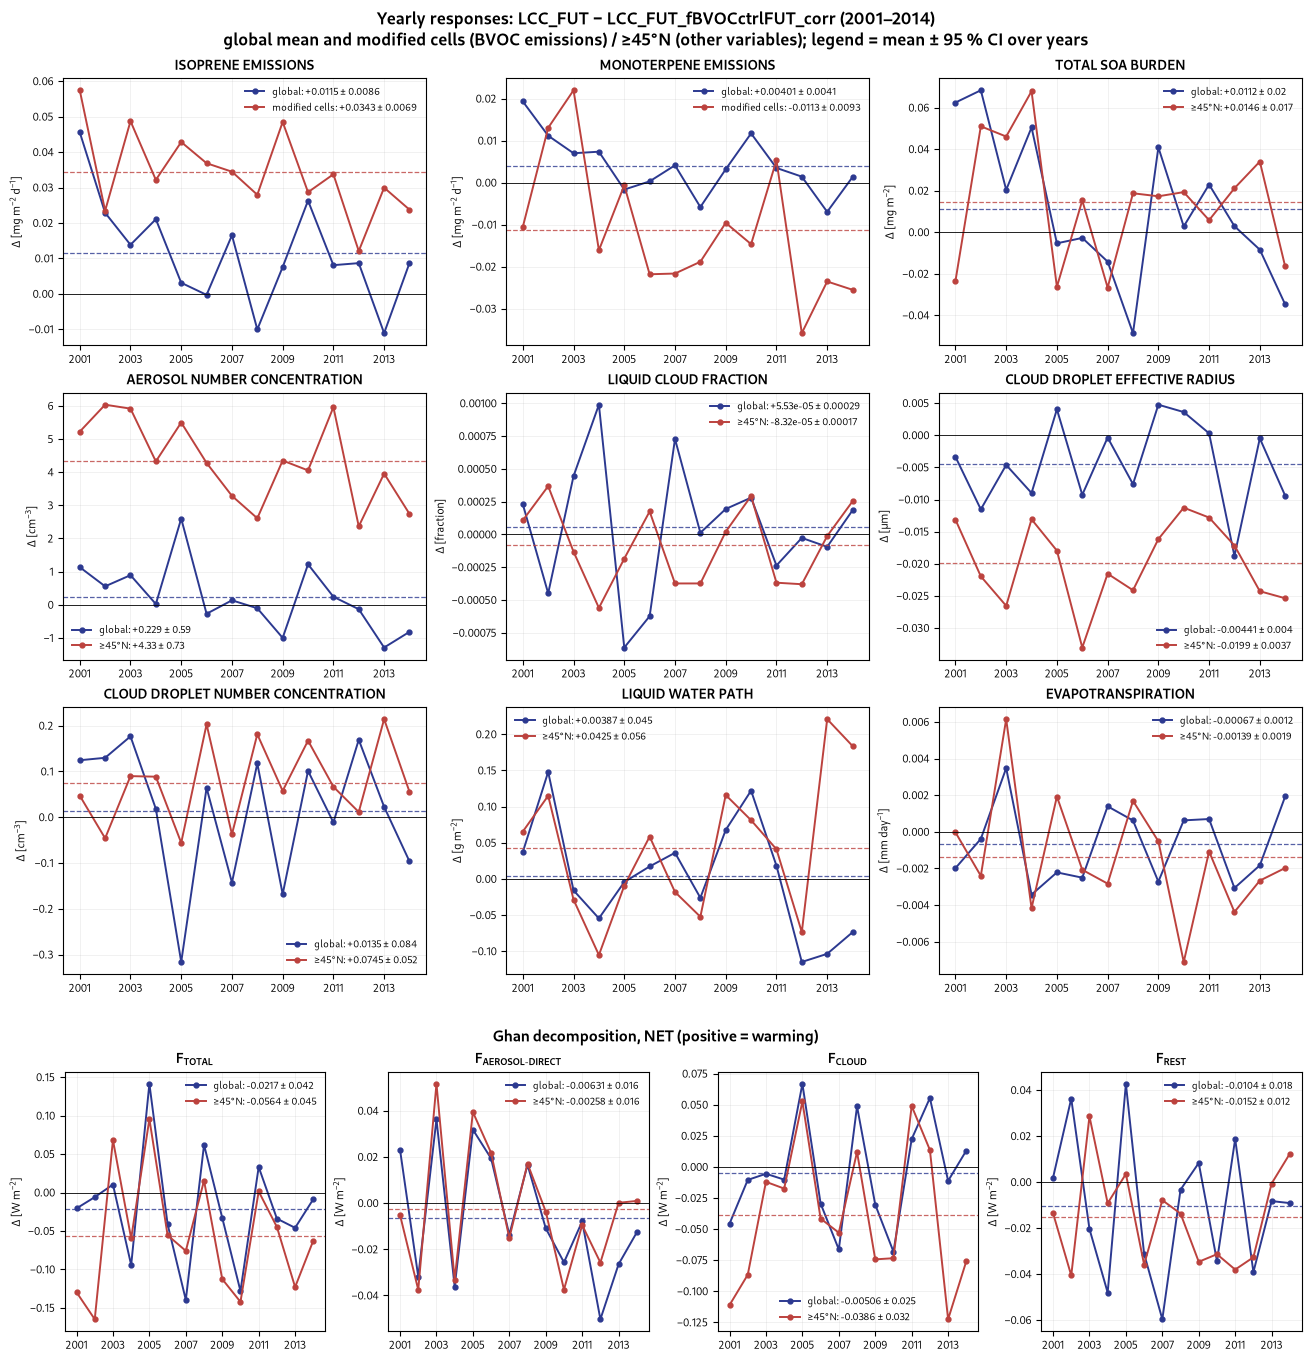

In [4]:
def plot_contrast(label, save=True):
    c1, c2 = CONTRASTS[label]
    sub = t[t.contrast == label]
    fig = plt.figure(figsize=(13, 13.5), constrained_layout=True)
    top, bottom = fig.subfigures(2, 1, height_ratios=[3, 1.05], hspace=0.04)
    axes = list(top.subplots(3, 3).ravel()) + list(bottom.subplots(1, 4))
    bottom.suptitle("Ghan decomposition, NET (positive = warming)", fontsize=11, fontweight="semibold")
    for ax, (key, title, cls, var, units, comp) in zip(axes, PANELS):
        for line in ("global", "regional"):
            d = sub[(sub.panel == key) & (sub.line == line)].sort_values("year")
            m, h = mean_ci(d.value)
            ax.plot(d.year, d.value, "o-", ms=3.5, lw=1.4, color=COLORS[line],
                    label=f"{'global' if line == 'global' else d.region.iloc[0]}: {m:+.3g} ± {h:.2g}")
            ax.axhline(m, color=COLORS[line], lw=0.9, ls="--", alpha=0.8)
        ax.axhline(0, color="black", lw=0.6)
        ax.set_title(title, fontsize=9.5, fontweight="semibold")
        ax.set_ylabel(f"Δ [{units}]", fontsize=8)
        ax.set_xticks(range(START_YEAR, END_YEAR + 1, 2))
        ax.tick_params(labelsize=7.5)
        ax.legend(fontsize=7, loc="best", frameon=False)
        ax.grid(alpha=0.25, lw=0.5)
    fig.suptitle(f"Yearly responses: {c1} − {c2} ({START_YEAR}–{END_YEAR})\n"
                 "global mean and modified cells (BVOC emissions) / ≥45°N (other variables); legend = mean ± 95 % CI over years",
                 fontsize=12, fontweight="bold")
    if save:
        path = FIGDIR / f"timeseries_{label}_{START_YEAR}_{END_YEAR}.png"
        fig.savefig(path, dpi=200, bbox_inches="tight")
        print("Saved", path)
    return fig

for label in CONTRASTS:
    fig = plot_contrast(label)
    plt.show(); plt.close(fig)


## 3. Absolute values of every nudged run (no differences)

Same 13 panels, same regions (modified cells for ISOP/MTERP, ≥45°N for the rest), yearly means of each run itself.
**4 figures:** {PD, FUT} × {global, regional}; one line per run. PD and FUT are separate because their levels differ far more than the runs within a period.

- **Colours:** CTRL navy, LCC red; fBVOC runs on LCC land: plum = CTRL_PD emissions, orange = CTRL_FUT emissions, teal = LCC_PD emissions; **dashed navy** = CTRL land with its own emissions prescribed (artefact runs).
- **Ghan panels, absolute:** F_TOTAL = net TOA flux (down positive); F_AEROSOL-DIRECT = F − F_clean (aerosol direct effect); F_CLOUD = F_clean − F_clean,clear (cloud radiative effect without aerosol); F_REST = F_clean,clear (clear-sky, aerosol-free net flux). F_TOTAL = sum of the three. Global annual F_TOTAL is not 0 in these nudged, fixed-SST runs.
- `LCC_PD_fBVOClccPD` is the 3-yr test (2000–2002), so only 2001–2002 remain after the spin-up year.
- Absolute means of in-cloud quantities (droplet radius, number) are yearly ratios of means with FCTL ≥ 0.01, as in the maps; global CLM fields (ET) = global land mean.
- **In-cloud caveat:** cells with FCTL < 0.01 are masked in each run separately, so for droplet radius and number the difference of these absolute means ≠ the §1 mean difference (cells valid in both runs). Checked below: all other fields agree to < 1e-6; for global droplet radius the gap (≈0.01 µm) exceeds the typical LCC_PD − CTRL_PD difference (≈0.003 µm), so do not read run-to-run differences of the global in-cloud lines.


In [5]:
import re
RUNS = {
    "PD":  ["CTRL_PD", "LCC_PD", "LCC_PD_fBVOCctrlPD", "LCC_PD_fBVOClccPD", "CTRL_PD_fBVOCctrlPD"],
    "FUT": ["CTRL_FUT", "LCC_FUT", "LCC_FUT_fBVOCctrlPD", "LCC_FUT_fBVOCctrlFUT", "LCC_FUT_fBVOClccPD",
            "CTRL_FUT_fBVOCctrlFUT"],
}
def run_style(alias):
    if alias.startswith("CTRL"):
        return pal.NAVY, ("--" if "fBVOC" in alias else "-")
    return {"ctrlPD": pal.PLUM, "ctrlFUT": pal.ORANGE, "lccPD": pal.TEAL}.get(alias.split("fBVOC")[-1], pal.RED), "-"

def run_span(alias, cls, comp):
    """(y0, y1) of the single processed file of this run and class."""
    files = sorted(fm.POSTPROCESSED_DIR.glob(f"{alias}_{comp}_{cls}_*-*.nc"))
    assert len(files) == 1, (alias, cls, [f.name for f in files])
    return tuple(int(x) for x in re.search(r"_(\d{4})-(\d{4})\.nc$", files[0].name).groups())

rows, opened = [], {}
for period, aliases in RUNS.items():
    for alias in aliases:
        for key, title, cls, var, units, comp in PANELS:
            if (alias, cls, comp) not in opened:
                y0, y1 = run_span(alias, cls, comp)
                opened[alias, cls, comp] = fm.open_class(alias, cls, y0, y1, comp)
            ds = opened[alias, cls, comp]
            f = fm.yearly_field(ds, var)
            assert np.allclose(ds["lat"], refs[comp]["lat"]) and np.allclose(ds["lon"], refs[comp]["lon"])
            f = f.assign_coords(lat=refs[comp]["lat"], lon=refs[comp]["lon"])   # CAM/CLM coords differ by ~1e-13
            for line, region in (("global", "global"), ("regional", REGIONAL.get(key, "≥45°N"))):
                r = fm.regional(f, refs[comp], masks[comp][region])
                rows += [dict(period=period, run=alias, panel=key, variable=var, line=line, region=region,
                              units=units, year=int(y), value=float(v)) for y, v in zip(r["year"].values, r.values)]
a = pd.DataFrame(rows)

g = a[a.panel.str.startswith("NET_")].pivot_table(index=["run", "line", "year"], columns="variable", values="value")
err = (g["NET_dir"] + g["NET_cloud"] + g["NET_rest"] - g["NET_toa"]).abs().max()
print(f"Ghan closure (absolute regional means): {err:.1e} W m-2"); assert err < 1e-3
print(a.groupby("run").year.agg(["min", "max"]).drop_duplicates())

ABS_TABLE = TABLE.with_name(f"timeseries_absolute_{START_YEAR}_{END_YEAR}.csv")
a.to_csv(ABS_TABLE, index=False); print("Saved", ABS_TABLE)

# consistency: absolute differences reproduce section 1 (Total_PD, ≥45°N / modified cells)
chk = a[a.run.isin(["LCC_PD", "CTRL_PD"])].pivot_table(index=["panel", "line", "year"], columns="run", values="value")
ref = t[t.contrast == "Total_PD"].set_index(["panel", "line", "year"]).value
err = ((chk.LCC_PD - chk.CTRL_PD) - ref).abs().groupby(["panel", "line"]).max()
print("max |(LCC_PD - CTRL_PD) - section-1 difference| per panel:")
print(pd.DataFrame({"max err": err, "mean |diff|": ref.abs().groupby(["panel", "line"]).mean()}).sort_values("max err", ascending=False).head(6))
# exact for all fields except the in-cloud ones: their FCTL >= 0.01 mask differs between runs
assert err.drop(["actnl", "actrel"], level="panel").max() < 1e-6


Ghan closure (absolute regional means): 5.7e-08 W m-2
                    min   max
run                          
CTRL_FUT           2001  2014
LCC_PD_fBVOClccPD  2001  2002
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/tables/timeseries_absolute_2001_2014.csv
max |(LCC_PD - CTRL_PD) - section-1 difference| per panel:
                      max err  mean |diff|
panel  line                               
actnl  global    6.294003e-02     0.099464
       regional  1.885386e-02     0.105201
actrel global    1.103302e-02     0.003194
       regional  5.471426e-04     0.011352
n_aer  global    7.024159e-12     1.200690
       regional  4.529710e-12     6.057226


In [6]:
# mean over years per run (regional line), for reading the levels
with pd.option_context("display.max_rows", 200, "display.width", 200):
    display(a[a.line == "regional"].groupby(["period", "panel", "run"], sort=False).value.mean()
            .unstack("run").round(4))


run                 CTRL_PD     LCC_PD  LCC_PD_fBVOCctrlPD  LCC_PD_fBVOClccPD  CTRL_PD_fBVOCctrlPD  CTRL_FUT   LCC_FUT  LCC_FUT_fBVOCctrlPD  LCC_FUT_fBVOCctrlFUT  LCC_FUT_fBVOClccPD  \
period panel                                                                                                                                                                            
PD     sfisop        0.3914     0.4143              0.3913             0.4141               0.3913       NaN       NaN                  NaN                   NaN                 NaN   
       sfmterp       0.4721     0.4754              0.4719             0.4752               0.4719       NaN       NaN                  NaN                   NaN                 NaN   
       soa_tot       1.3014     1.3020              1.3297             1.2791               1.3287       NaN       NaN                  NaN                   NaN                 NaN   
       n_aer      1005.6949  1011.7521           1022.2488           998.6404            1019.1882       NaN       NaN                  NaN                   NaN                 NaN   
       fctl          0.1204     0.1200              0.1201             0.1213               0.1204       NaN       NaN                  NaN                   NaN                 NaN   
       actrel       11.2971    11.2858             11.2756            11.2484              11.2735       NaN       NaN                  NaN                   NaN                 NaN   
       actnl        41.6831    41.7219             42.0035            42.2165              42.0445       NaN       NaN                  NaN                   NaN                 NaN   
       lwp          69.9293    69.7305             69.7177            70.2637              69.9638       NaN       NaN                  NaN                   NaN                 NaN   
       et            0.7190     0.7234              0.7221             0.7158               0.7174       NaN       NaN                  NaN                   NaN                 NaN   
       NET_toa     -69.9230   -69.6831            -69.7105           -70.1144             -69.9782       NaN       NaN                  NaN                   NaN                 NaN   
       NET_dir      -0.9962    -1.0086             -1.0139            -0.9420              -1.0002       NaN       NaN                  NaN                   NaN                 NaN   
       NET_cloud   -25.7747   -25.8348            -25.8639           -26.0243             -25.8231       NaN       NaN                  NaN                   NaN                 NaN   
       NET_rest    -43.1521   -42.8396            -42.8326           -43.1481             -43.1549       NaN       NaN                  NaN                   NaN                 NaN   
FUT    sfisop           NaN        NaN                 NaN                NaN                  NaN    1.1850    1.2194               0.3913                1.1845              0.4141   
       sfmterp          NaN        NaN                 NaN                NaN                  NaN    2.1442    2.1330               0.4719                2.1432              0.4752   
       soa_tot          NaN        NaN                 NaN                NaN                  NaN    3.8775    3.8897               1.3215                3.9758              1.3207   
       n_aer            NaN        NaN                 NaN                NaN                  NaN  868.7670  875.8140             666.8375              897.2582            668.7129   
       fctl             NaN        NaN                 NaN                NaN                  NaN    0.1503    0.1496               0.1493                0.1498              0.1492   
       actrel           NaN        NaN                 NaN                NaN                  NaN   12.3734   12.3599              12.8757               12.3482             12.8666   
       actnl            NaN        NaN                 NaN                NaN                  NaN   30.7176   30.7

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/timeseries/timeseries_absolute_PD_global_2001_2014.png


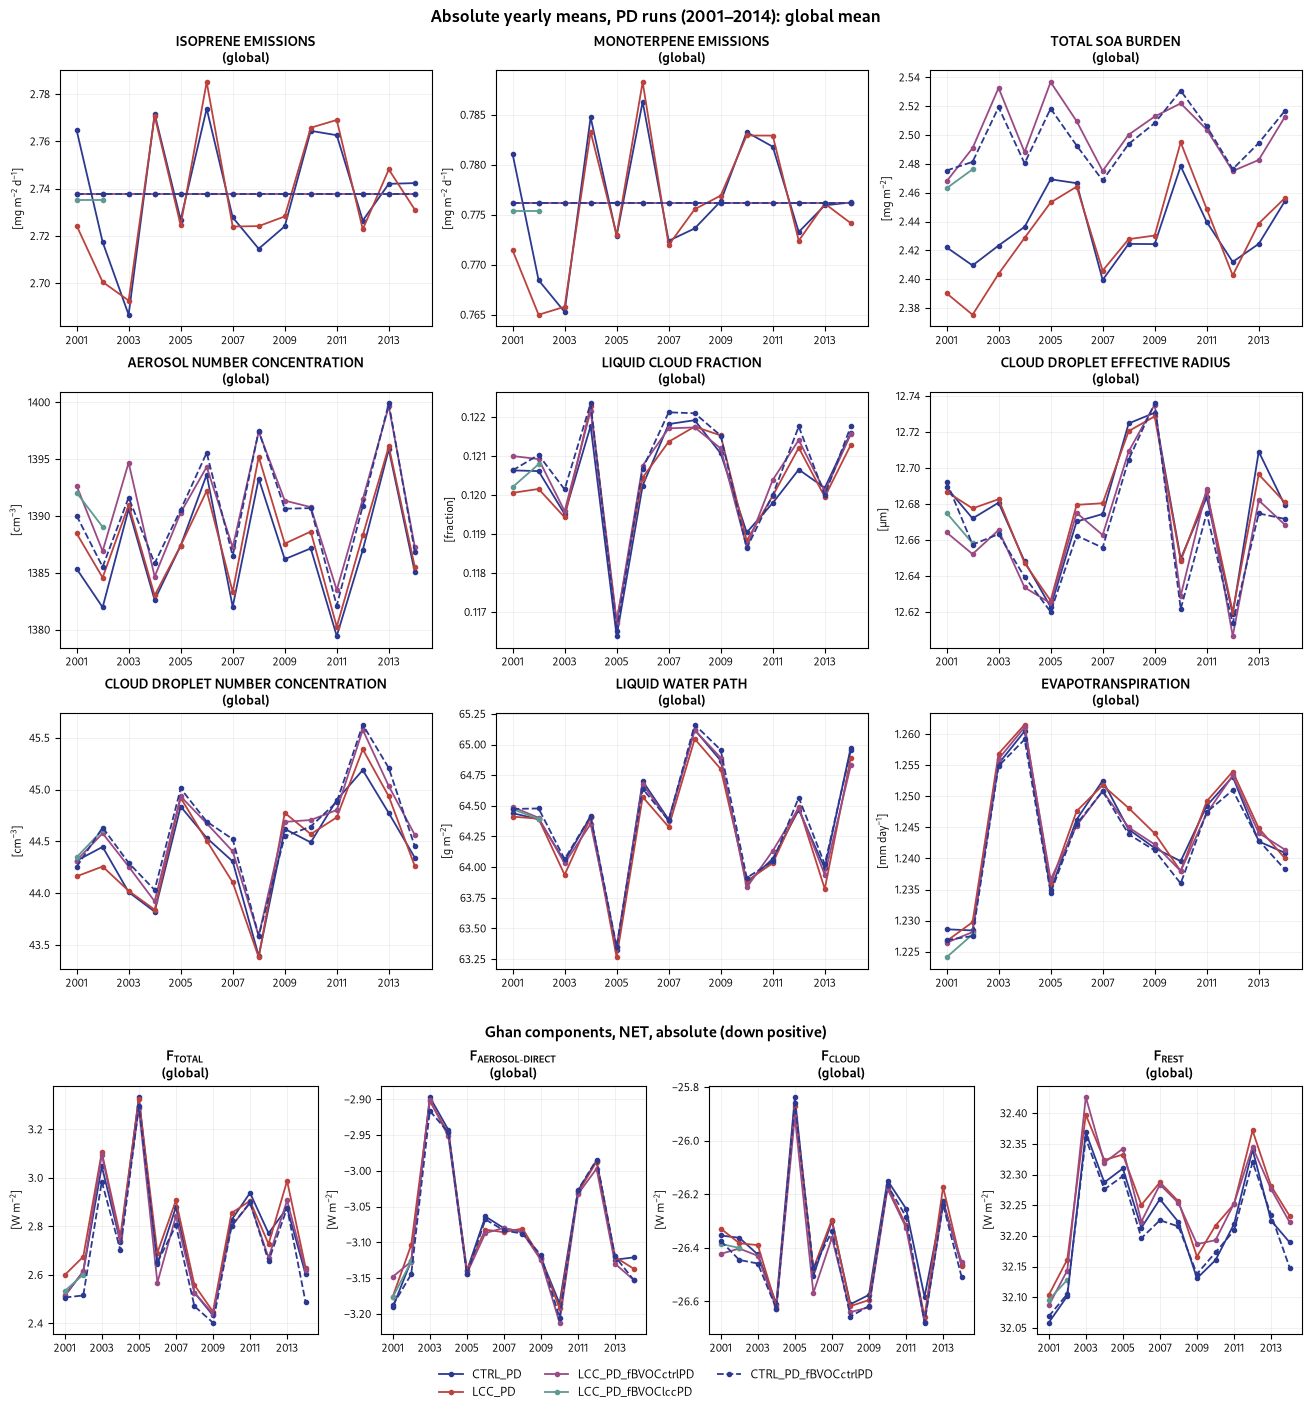

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/timeseries/timeseries_absolute_PD_regional_2001_2014.png


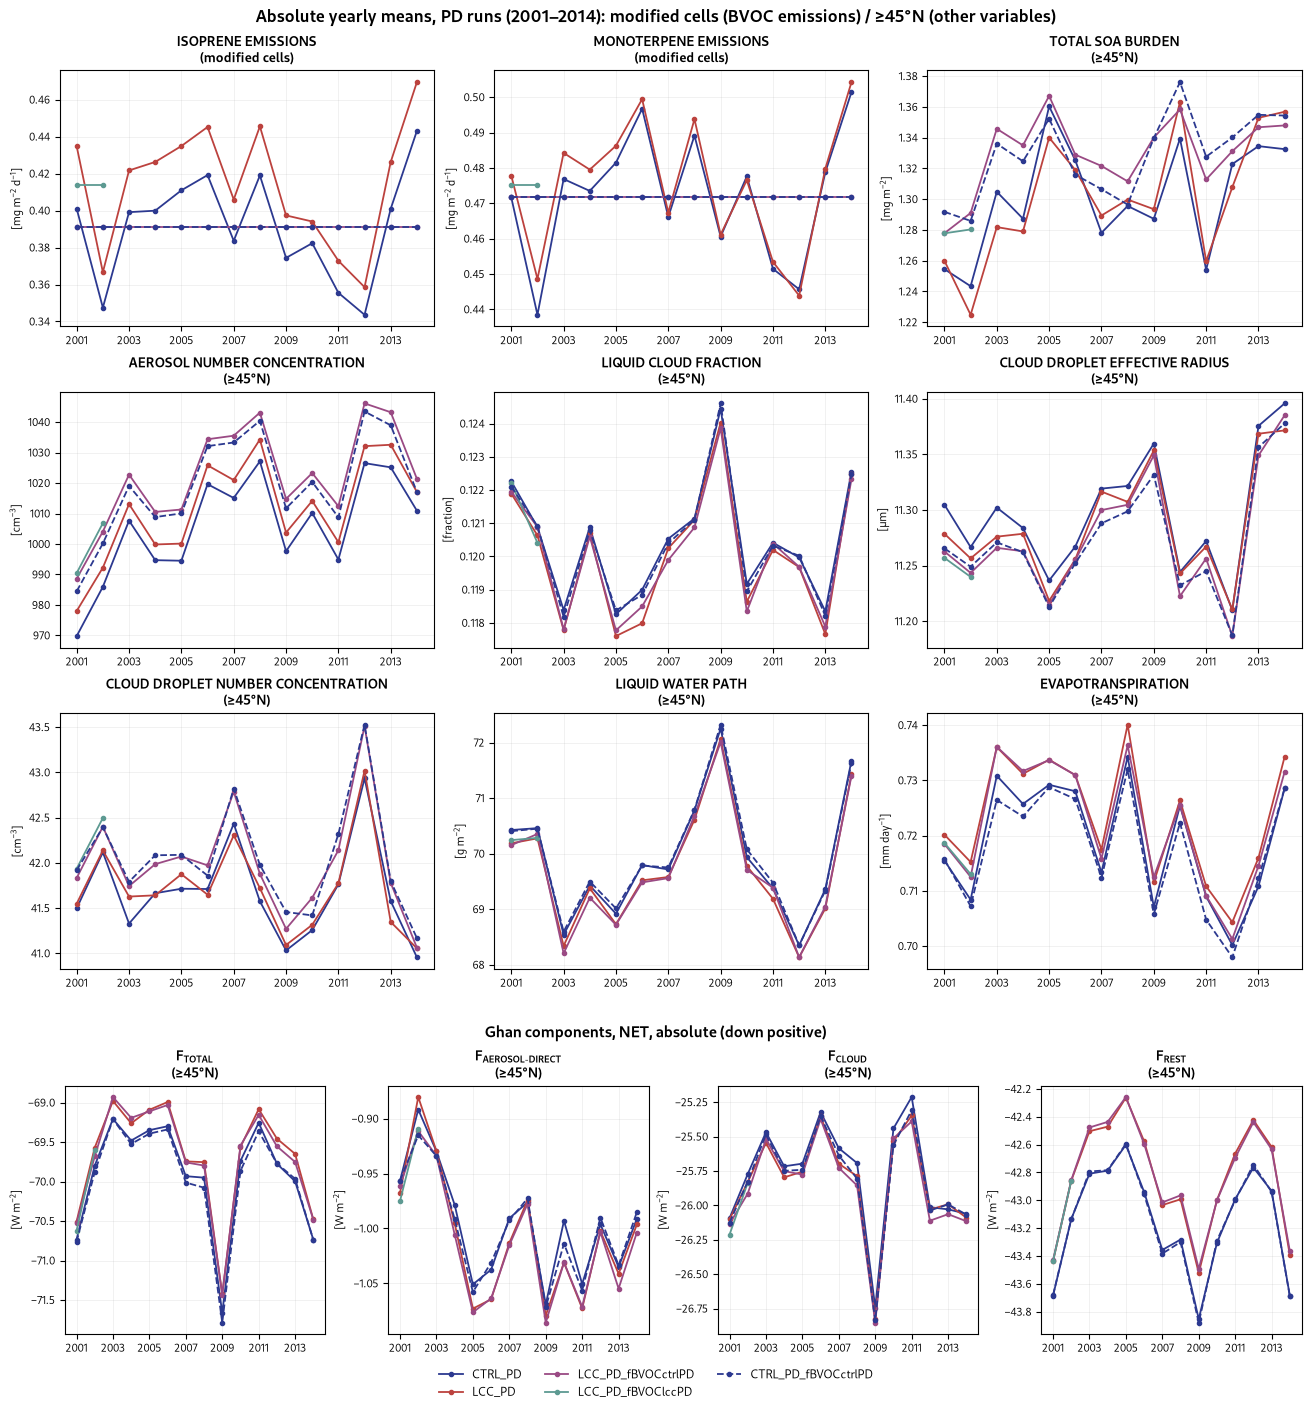

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/timeseries/timeseries_absolute_FUT_global_2001_2014.png


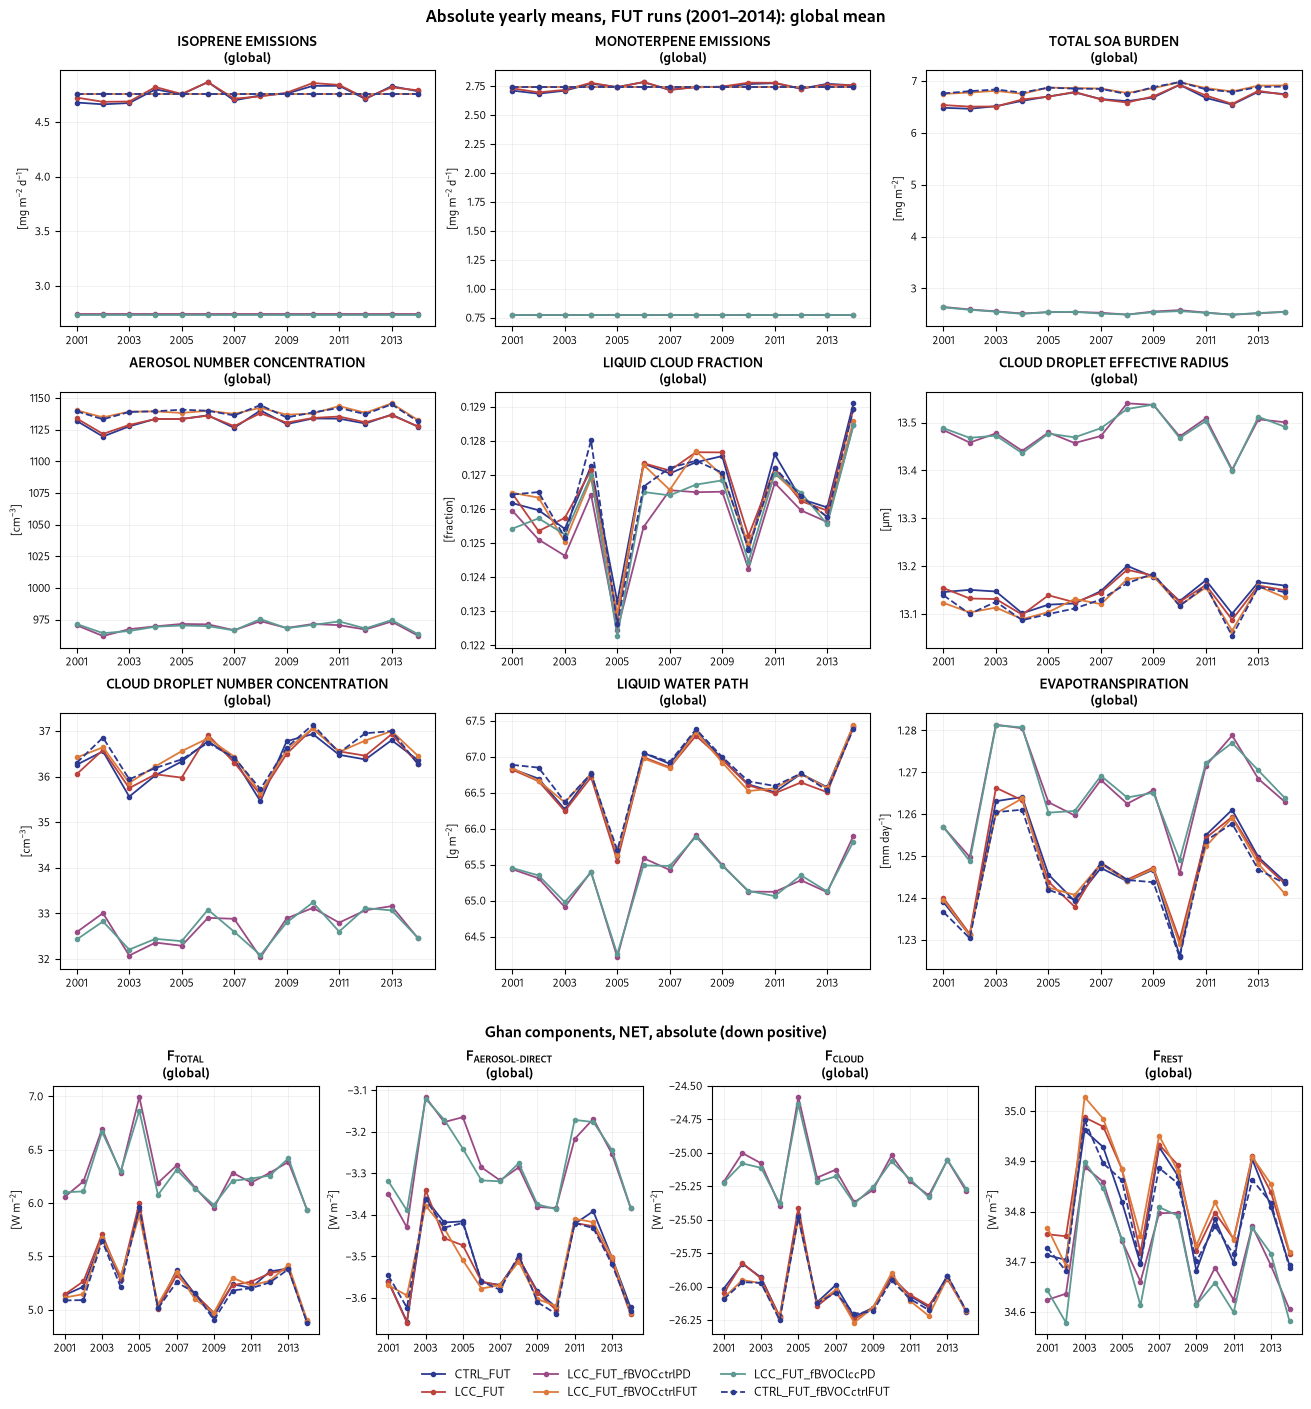

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/timeseries/timeseries_absolute_FUT_regional_2001_2014.png


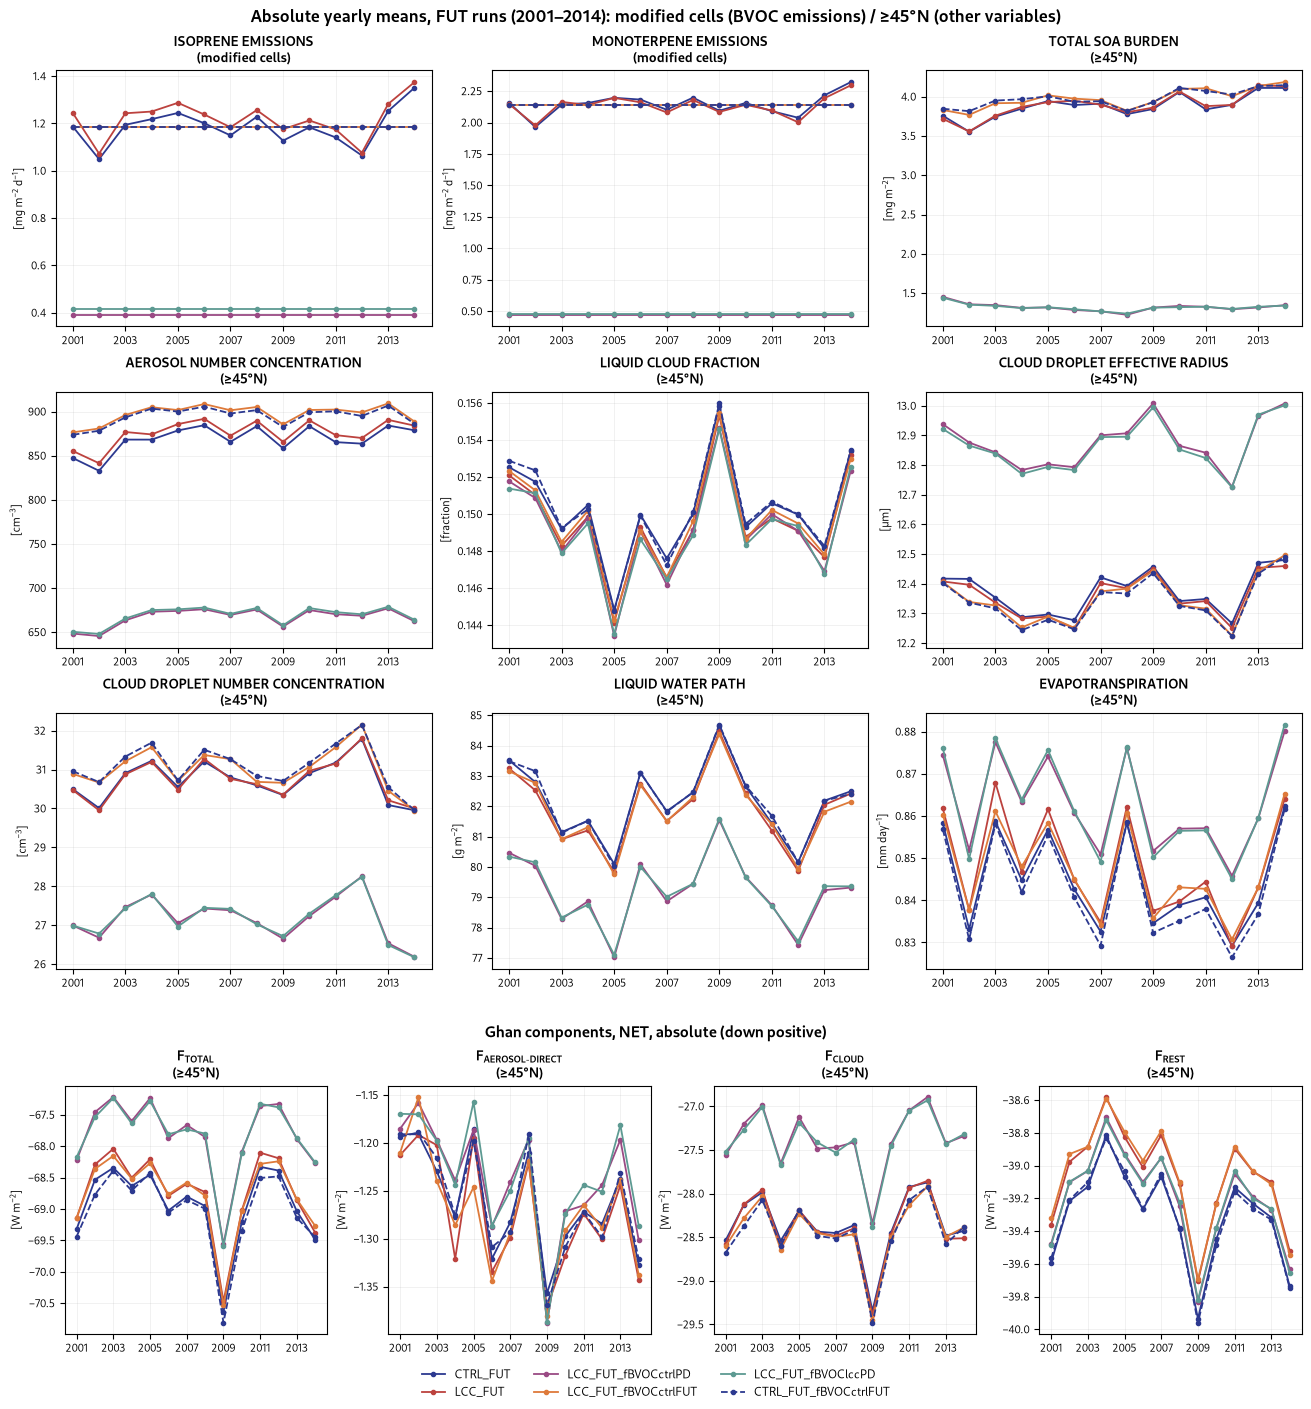

In [7]:
def plot_absolute(period, line, save=True):
    sub = a[(a.period == period) & (a.line == line)]
    fig = plt.figure(figsize=(13, 14), constrained_layout=True)
    top, bottom = fig.subfigures(2, 1, height_ratios=[3, 1.05], hspace=0.04)
    axes = list(top.subplots(3, 3).ravel()) + list(bottom.subplots(1, 4))
    bottom.suptitle("Ghan components, NET, absolute (down positive)", fontsize=11, fontweight="semibold")
    for ax, (key, title, cls, var, units, comp) in zip(axes, PANELS):
        d = sub[sub.panel == key]
        for alias in RUNS[period]:
            r = d[d.run == alias].sort_values("year")
            color, ls = run_style(alias)
            ax.plot(r.year, r.value, marker="o", ms=3, lw=1.3, ls=ls, color=color, label=alias)
        region = d.region.iloc[0]
        ax.set_title(f"{title}\n({region})", fontsize=9.5, fontweight="semibold")
        ax.set_ylabel(f"[{units}]", fontsize=8)
        ax.set_xticks(range(START_YEAR, END_YEAR + 1, 2)); ax.tick_params(labelsize=7.5)
        ax.grid(alpha=0.25, lw=0.5)
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc="outside lower center", ncol=3, fontsize=8.5, frameon=False)
    where = "global mean" if line == "global" else "modified cells (BVOC emissions) / ≥45°N (other variables)"
    fig.suptitle(f"Absolute yearly means, {period} runs ({START_YEAR}–{END_YEAR}): {where}",
                 fontsize=12, fontweight="bold")
    if save:
        path = FIGDIR / f"timeseries_absolute_{period}_{line}_{START_YEAR}_{END_YEAR}.png"
        fig.savefig(path, dpi=200, bbox_inches="tight"); print("Saved", path)
    return fig

for period in RUNS:
    for line in ("global", "regional"):
        fig = plot_absolute(period, line)
        plt.show(); plt.close(fig)
